# Wine Clustering – K-Means + PCA

**Goal:** Find natural groups of wines from their chemical properties (unsupervised – no labels).

**Dataset:** `wine-clustering.csv` – 178 wines, 13 chemical features

**Approach:** RobustScaler / StandardScaler → elbow method & silhouette score for K = 2…10 → K-Means → PCA to 2 components for visualization.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## Load the data

In [2]:
df=pd.read_csv('../data/wine-clustering.csv')

In [3]:
df

,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735
...,...,...,...,...,...,...,...,...,...,...,...,...,...
173,13.71,5.65,2.45,20.5,95,1.68,0.61,0.52,1.06,7.70,0.64,1.74,740
174,13.40,3.91,2.48,23.0,102,1.80,0.75,0.43,1.41,7.30,0.70,1.56,750
175,13.27,4.28,2.26,20.0,120,1.59,0.69,0.43,1.35,10.20,0.59,1.56,835
176,13.17,2.59,2.37,20.0,120,1.65,0.68,0.53,1.46,9.30,0.60,1.62,840


## Exploratory data analysis

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Alcohol               178 non-null    float64
 1   Malic_Acid            178 non-null    float64
 2   Ash                   178 non-null    float64
 3   Ash_Alcanity          178 non-null    float64
 4   Magnesium             178 non-null    int64  
 5   Total_Phenols         178 non-null    float64
 6   Flavanoids            178 non-null    float64
 7   Nonflavanoid_Phenols  178 non-null    float64
 8   Proanthocyanins       178 non-null    float64
 9   Color_Intensity       178 non-null    float64
 10  Hue                   178 non-null    float64
 11  OD280                 178 non-null    float64
 12  Proline               178 non-null    int64  
dtypes: float64(11), int64(2)
memory usage: 18.2 KB


In [5]:
df.describe()

,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000


In [6]:
df.shape

(178, 13)

In [7]:
df.isnull().sum()

Alcohol                 0
Malic_Acid              0
Ash                     0
Ash_Alcanity            0
Magnesium               0
Total_Phenols           0
Flavanoids              0
Nonflavanoid_Phenols    0
Proanthocyanins         0
Color_Intensity         0
Hue                     0
OD280                   0
Proline                 0
dtype: int64

## Feature distributions

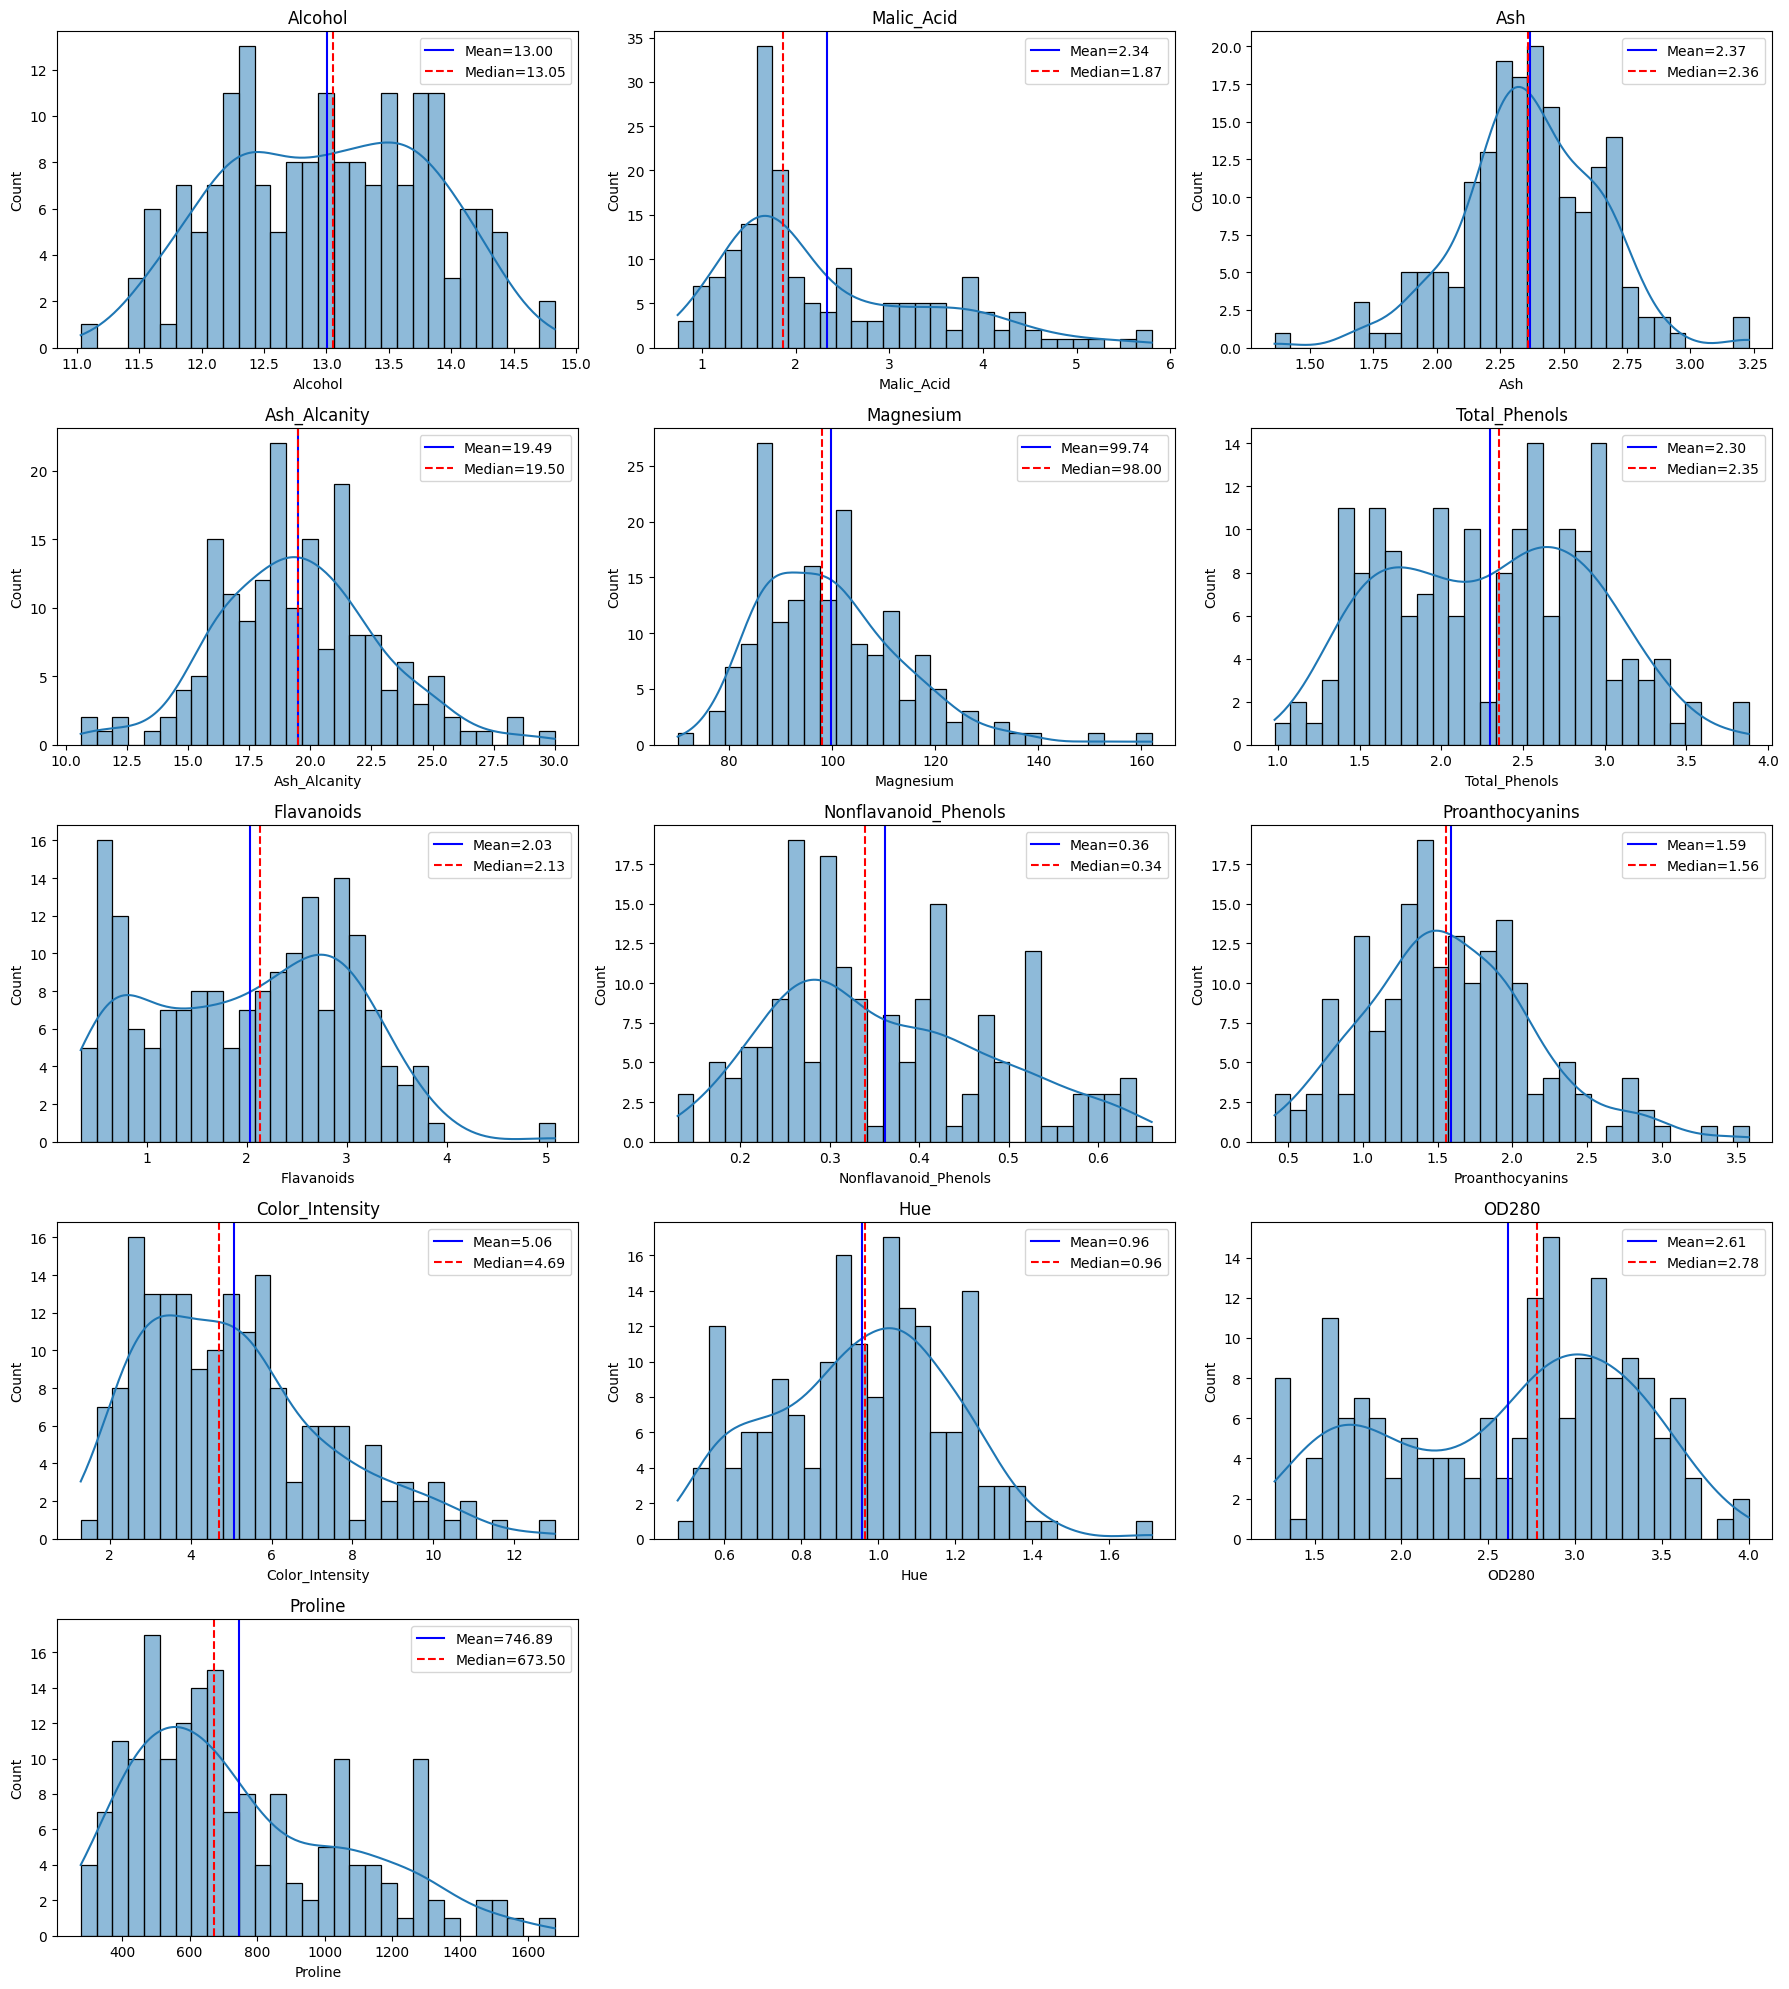

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/wine-clustering.csv")

features = df.columns

n_cols = 3
n_rows = (len(features) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 4))
axes = axes.flatten()

for i, col in enumerate(features):

    sns.histplot(data=df, x=col, kde=True, bins=30, ax=axes[i])

    mean_val = df[col].mean()
    median_val = df[col].median()

    axes[i].axvline(mean_val,
                    color="blue",
                    linestyle="-",
                    label=f"Mean={mean_val:.2f}")

    axes[i].axvline(median_val,
                    color="red",
                    linestyle="--",
                    label=f"Median={median_val:.2f}")

    axes[i].set_title(col)
    axes[i].legend()

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

## Feature scaling

In [9]:
from sklearn.preprocessing import StandardScaler, RobustScaler


robust_cols = [
    "Alcohol",
    "Malic_Acid",
    "Magnesium",
    "Total_Phenols",
    "Flavanoids",
    "Nonflavanoid_Phenols",
    "Proanthocyanins",
    "Color_Intensity",
    "OD280",
    "Proline"
]


standard_cols = [
    "Ash",
    "Ash_Alcanity",
    "Hue"
]


robust_scaler = RobustScaler()
standard_scaler = StandardScaler()


df_scaled = df.copy()


df_scaled[robust_cols] = robust_scaler.fit_transform(df[robust_cols])


df_scaled[standard_cols] = standard_scaler.fit_transform(df[standard_cols])


df_scaled.head()

,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline
0,0.897338,-0.104730,0.232053,-1.169593,1.526316,0.420804,0.553892,-0.358209,1.050000,0.318792,0.362177,0.924949,0.808050
1,0.114068,-0.057432,-0.827996,-2.490847,0.105263,0.278960,0.374251,-0.477612,-0.392857,-0.104027,0.406051,0.503043,0.777090
2,0.083650,0.334459,1.109334,-0.268738,0.157895,0.420804,0.661677,-0.238806,1.792857,0.332215,0.318304,0.316430,1.055728
3,1.003802,0.057432,0.487926,-0.809251,0.789474,1.413712,0.811377,-0.597015,0.892857,1.043624,-0.427544,0.543611,1.664603
4,0.144487,0.489865,1.840403,0.451946,1.052632,0.420804,0.332335,0.298507,0.378571,-0.124161,0.362177,0.121704,0.126935


In [10]:
X = df_scaled

## Choosing K – elbow method & silhouette score

In [11]:
from sklearn.cluster import KMeans

wcss = []
k_range = range(1,11)
for k in k_range:
    kmean = KMeans(n_clusters=k,random_state=42,n_init=10)
    kmean.fit(X)
    wcss.append(kmean.inertia_)

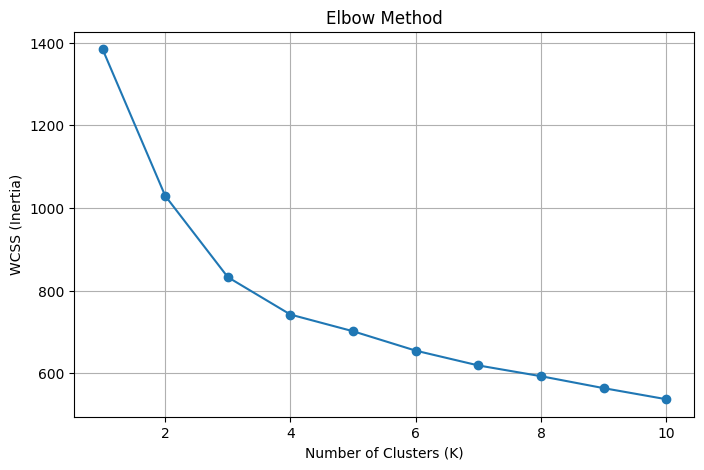

In [12]:
from sklearn.cluster import KMeans
plt.figure(figsize=(8,5))

plt.plot(range(1,11), wcss, marker='o')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS (Inertia)")
plt.title("Elbow Method")

plt.grid(True)
plt.show()

## Final K-Means model

In [13]:
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X)

In [14]:
X["Cluster"] = clusters

In [15]:
X["Cluster"].value_counts()

Cluster
2    55
1    49
3    37
0    37
Name: count, dtype: int64

## PCA visualization

In [16]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X.drop("Cluster", axis=1))

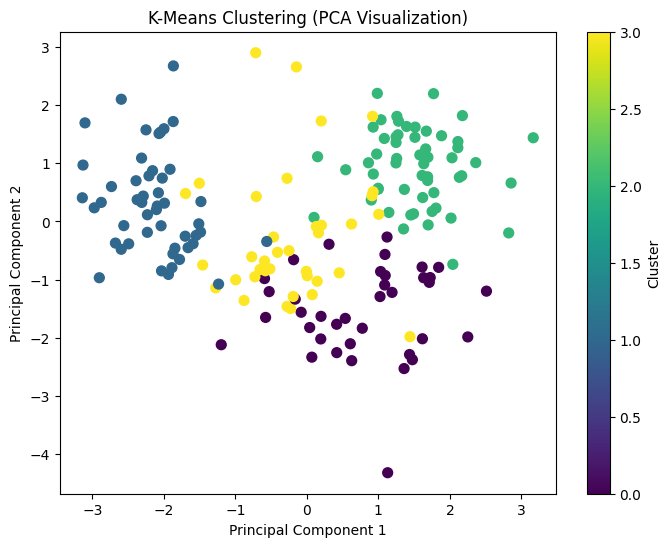

In [17]:
plt.figure(figsize=(8,6))

plt.scatter(
    X_pca[:,0],
    X_pca[:,1],
    c=clusters,
    cmap="viridis",
    s=50
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clustering (PCA Visualization)")
plt.colorbar(label="Cluster")
plt.show()

## Evaluation

In [18]:
from sklearn.metrics import silhouette_score

score = silhouette_score(
    X.drop("Cluster", axis=1),
    clusters
)

print("Silhouette Score =", score)

Silhouette Score = 0.24409328485388726


In [19]:
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(df_scaled)

    score = silhouette_score(df_scaled, labels)

    print(f"K = {k} --> Silhouette Score = {score:.4f}")

K = 2 --> Silhouette Score = 0.2377
K = 3 --> Silhouette Score = 0.2849
K = 4 --> Silhouette Score = 0.3263
K = 5 --> Silhouette Score = 0.3245
K = 6 --> Silhouette Score = 0.2143
K = 7 --> Silhouette Score = 0.1840
K = 8 --> Silhouette Score = 0.1709
K = 9 --> Silhouette Score = 0.1623
K = 10 --> Silhouette Score = 0.1579


## Results & conclusion

* Silhouette score peaks at **K = 4 (≈ 0.33)**, with K = 3 close behind (0.28); the elbow plot was used together with the silhouette score to pick K.
* The original wine data comes from 3 cultivars, so K-Means finds a structure close to the real one without using any labels.
* PCA (2 components) is used to visualize the clusters in 2D.